<a href="https://colab.research.google.com/github/Ghule-vaibhavi/-machine-learning-model/blob/main/decisiontree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Decision tree , Loan Approval Prediction

In [1]:
import pandas as pd

data = {
    "Income": [25000, 30000, 45000, 20000,
               60000, 35000, 50000, 28000],
    "Credit_Score": [550, 600, 700, 500,
                     750, 580, 680, 620],
    "Existing_Debt": ["Yes", "No", "No", "Yes",
                      "No", "Yes", "No", "Yes"],
    "Loan_Approved": ["No", "Yes", "Yes", "No",
                      "Yes", "No", "Yes", "No"]
}

df = pd.DataFrame(data)

print(df)

   Income  Credit_Score Existing_Debt Loan_Approved
0   25000           550           Yes            No
1   30000           600            No           Yes
2   45000           700            No           Yes
3   20000           500           Yes            No
4   60000           750            No           Yes
5   35000           580           Yes            No
6   50000           680            No           Yes
7   28000           620           Yes            No


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

X = df[["Income", "Credit_Score", "Existing_Debt"]]
y = df["Loan_Approved"]

preprocessor = ColumnTransformer([
    ("debt", OneHotEncoder(handle_unknown="ignore"),
     ["Existing_Debt"])
], remainder="passthrough")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [3]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         1
         Yes       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



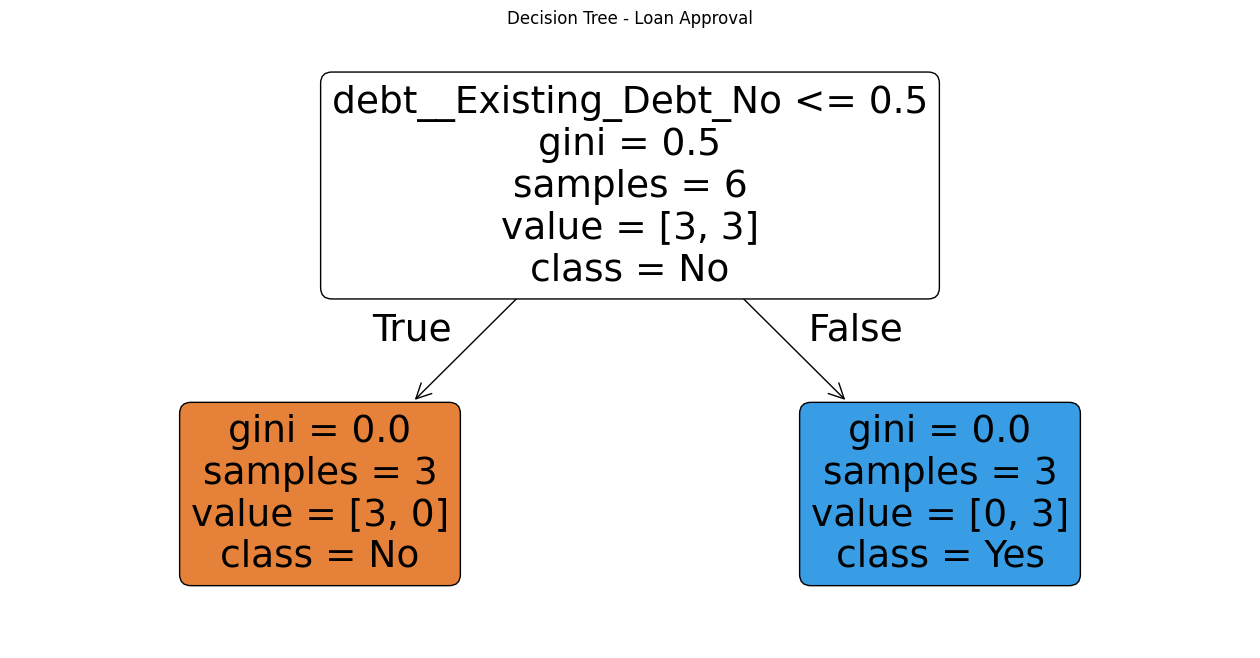

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree_model = model.named_steps["tree"]
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Loan Approval")
plt.show()

In [5]:
new_applicant = pd.DataFrame({
    "Income": [50000],
    "Credit_Score": [720],
    "Existing_Debt": ["No"]
})

prediction = model.predict(new_applicant)

print("Loan Approval Prediction:", prediction[0])

Loan Approval Prediction: Yes
